In [16]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import open3d as o3d
import networkx as nx
import plotly.graph_objects as go
from plotly.colors import qualitative

np.random.seed(42)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

workspace_root = Path.cwd() / 'data'
sample_dirs = sorted([p for p in workspace_root.glob('Lemon*') if p.is_dir()])

if not sample_dirs:
    raise FileNotFoundError('未发现 Lemon* 样本目录，请检查当前工作目录。')

default_sample = sample_dirs[0]
pointcloud_path = default_sample / 'pointcloud' / 'mergePointClouds.ply'
skeleton_path = default_sample / 'skeleton' / 'skeleton.txt'

print('工作目录:', workspace_root)
print('发现样本数:', len(sample_dirs))
print('默认样本:', default_sample.name)
print('默认点云文件:', pointcloud_path)
print('默认骨架文件:', skeleton_path)

工作目录: /root/lemonrl/data
发现样本数: 100
默认样本: Lemon00_01
默认点云文件: /root/lemonrl/data/Lemon00_01/pointcloud/mergePointClouds.ply
默认骨架文件: /root/lemonrl/data/Lemon00_01/skeleton/skeleton.txt


In [17]:
def load_pointcloud_ply(ply_file: Path) -> pd.DataFrame:
    """加载 .ply 点云为 DataFrame，尽力提取 branch_id。"""
    ply_file = Path(ply_file)
    if not ply_file.exists():
        raise FileNotFoundError(f'点云文件不存在: {ply_file}')

    try:
        if hasattr(o3d, 't') and hasattr(o3d.t, 'io'):
            tpcd = o3d.t.io.read_point_cloud(str(ply_file))
            try:
                xyz = tpcd.point['positions'].numpy()
            except Exception as e_pos:
                raise ValueError(f'点云缺少 positions 字段或不可访问: {e_pos}') from e_pos
            if xyz.ndim != 2 or xyz.shape[1] < 3:
                raise ValueError('positions 维度异常，无法解析 xyz。')

            branch_candidates = ['branch_id', 'branch', 'label', 'labels', 'segment_id', 'scalar_branch_id']
            branch_id = None
            branch_field_used = None

            # 1) 先尝试语义明确的分支字段
            for name in branch_candidates:
                try:
                    branch_raw = tpcd.point[name].numpy().reshape(-1)
                    if branch_raw.shape[0] == xyz.shape[0]:
                        branch_id = pd.Series(branch_raw).round().astype('Int64').fillna(0).astype(int).to_numpy()
                        branch_field_used = name
                        break
                except Exception:
                    continue

            # 2) 若无标准字段，尝试从 attr 字段推断离散分支 ID
            if branch_id is None:
                infer_candidates = ['attr1', 'attr2', 'scalar_attr1', 'scalar_attr2']
                for name in infer_candidates:
                    try:
                        raw = tpcd.point[name].numpy().reshape(-1)
                    except Exception:
                        continue

                    if raw.shape[0] != xyz.shape[0]:
                        continue

                    raw = np.asarray(raw, dtype=float)
                    finite_mask = np.isfinite(raw)
                    if not finite_mask.any():
                        continue

                    finite_vals = raw[finite_mask]
                    rounded = np.round(finite_vals)
                    int_ratio = float(np.mean(np.isclose(finite_vals, rounded, atol=1e-4)))
                    unique_count = int(np.unique(rounded.astype(np.int64)).size)

                    # 分支 ID 常见特征：近整数且类别数适中
                    if int_ratio >= 0.98 and 1 < unique_count < min(5000, max(20, int(0.5 * raw.shape[0]))):
                        full_rounded = np.round(np.nan_to_num(raw, nan=0.0)).astype(int)
                        branch_id = full_rounded
                        branch_field_used = name
                        warnings.warn(f'未找到标准 branch_id 字段，已使用 {name} 推断分支 ID。')
                        break

            if branch_id is None:
                warnings.warn('未在 .ply 中检测到可用 branch_id/attr 字段，已回退为单一分支 branch_id=0。')
                branch_id = np.zeros(xyz.shape[0], dtype=int)
            elif branch_field_used is not None and branch_field_used in branch_candidates:
                print(f'点云分支字段: {branch_field_used}')

            pc_df = pd.DataFrame({
                'x': xyz[:, 0],
                'y': xyz[:, 1],
                'z': xyz[:, 2],
                'branch_id': branch_id
            })
            return pc_df

        legacy_pcd = o3d.io.read_point_cloud(str(ply_file))
        xyz = np.asarray(legacy_pcd.points)
        if xyz.size == 0:
            raise ValueError('点云为空。')

        warnings.warn('Open3D 旧接口无法读取自定义属性，已使用 branch_id=0。')
        return pd.DataFrame({
            'x': xyz[:, 0],
            'y': xyz[:, 1],
            'z': xyz[:, 2],
            'branch_id': np.zeros(xyz.shape[0], dtype=int)
        })

    except Exception as e:
        raise RuntimeError(f'读取点云失败: {ply_file}\n原因: {e}') from e


def load_skeleton_txt(skel_file: Path) -> pd.DataFrame:
    """加载骨架 txt 为 DataFrame。"""
    skel_file = Path(skel_file)
    if not skel_file.exists():
        raise FileNotFoundError(f'骨架文件不存在: {skel_file}')

    col_names = ['x', 'y', 'z', 'r', 'parent_node_index', 'branch_id']

    try:
        skel_df = pd.read_csv(
            skel_file,
            sep=r'\s+',
            header=None,
            names=col_names,
            engine='python'
        )

        if skel_df.shape[1] != 6:
            raise ValueError(f'骨架列数异常，期望 6 列，实际 {skel_df.shape[1]} 列。')

        numeric_cols = ['x', 'y', 'z', 'r', 'parent_node_index', 'branch_id']
        for c in numeric_cols:
            skel_df[c] = pd.to_numeric(skel_df[c], errors='coerce')

        if skel_df[numeric_cols].isna().any().any():
            raise ValueError('骨架数据包含无法转换为数值的字段。')

        skel_df['node_id'] = np.arange(1, len(skel_df) + 1, dtype=int)
        skel_df['parent_node_index'] = skel_df['parent_node_index'].round().astype(int)
        skel_df['branch_id'] = skel_df['branch_id'].round().astype(int)

        return skel_df

    except Exception as e:
        raise RuntimeError(f'读取骨架失败: {skel_file}\n原因: {e}') from e


point_df = load_pointcloud_ply(pointcloud_path)
skeleton_df = load_skeleton_txt(skeleton_path)

print('点云数据维度:', point_df.shape)
print('骨架数据维度:', skeleton_df.shape)
display(point_df.head())
display(skeleton_df.head())

点云数据维度: (56742, 4)
骨架数据维度: (6225, 7)


/tmp/ipykernel_26352/3465034137.py:59: UserWarning: 未找到标准 branch_id 字段，已使用 attr1 推断分支 ID。
  warnings.warn(f'未找到标准 branch_id 字段，已使用 {name} 推断分支 ID。')


,x,y,z,branch_id
0,11.418770,25.448769,-0.441174,1
1,11.356191,25.906881,2.451950,1
2,11.247910,25.898426,6.510223,1
3,11.470234,25.780403,1.770921,1
4,11.364529,25.899611,6.863037,1


,x,y,z,r,parent_node_index,branch_id,node_id
0,11.506658,25.905943,3.868585,0.119006,1,0,1
1,11.468893,25.895973,3.967917,0.118696,1,0,2
2,11.471699,25.845675,4.069625,0.117623,1,0,3
3,11.492868,25.798210,4.171206,0.117524,1,0,4
4,11.494027,25.759944,4.272445,0.117381,1,0,5


In [18]:
def build_skeleton_digraph(skel_df: pd.DataFrame):
    """根据骨架表构建有向图并返回根节点列表。"""
    required_cols = {'node_id', 'x', 'y', 'z', 'r', 'parent_node_index', 'branch_id'}
    missing = required_cols - set(skel_df.columns)
    if missing:
        raise ValueError(f'骨架表缺少必要列: {missing}')

    g = nx.DiGraph()

    for row in skel_df.itertuples(index=False):
        g.add_node(
            int(row.node_id),
            x=float(row.x),
            y=float(row.y),
            z=float(row.z),
            r=float(row.r),
            branch_id=int(row.branch_id),
            parent_node_index=int(row.parent_node_index),
        )

    node_set = set(g.nodes())
    provisional_roots = set()

    for row in skel_df.itertuples(index=False):
        child = int(row.node_id)
        parent = int(row.parent_node_index)

        is_root = (parent <= 0) or (parent not in node_set) or (parent == child)
        if is_root:
            provisional_roots.add(child)
        else:
            g.add_edge(parent, child)

    indeg_roots = {n for n, d in g.in_degree() if d == 0}
    roots = sorted(indeg_roots.union(provisional_roots))

    return g, roots


skeleton_graph, root_nodes = build_skeleton_digraph(skeleton_df)

print('图节点数:', skeleton_graph.number_of_nodes())
print('图边数:', skeleton_graph.number_of_edges())
print('根节点数:', len(root_nodes))
print('根节点示例(最多10个):', root_nodes[:10])

图节点数: 6225
图边数: 6224
根节点数: 1
根节点示例(最多10个): [1]


In [19]:
def compute_bbox(df_xyz: pd.DataFrame):
    """计算 xyz 包围盒。"""
    mins = df_xyz[['x', 'y', 'z']].min()
    maxs = df_xyz[['x', 'y', 'z']].max()
    return mins, maxs


num_points = len(point_df)
num_nodes = len(skeleton_df)

branches_union = set(point_df['branch_id'].unique()).union(set(skeleton_df['branch_id'].unique()))
num_branches = len(branches_union)

tree_xyz = pd.concat([
    point_df[['x', 'y', 'z']],
    skeleton_df[['x', 'y', 'z']]
], axis=0, ignore_index=True)
bbox_min, bbox_max = compute_bbox(tree_xyz)

print('========== 数据统计 ==========' )
print('点云点数:', num_points)
print('骨架节点数:', num_nodes)
print('唯一分支数:', num_branches)
print('包围盒最小值 [x_min, y_min, z_min]:', bbox_min.values)
print('包围盒最大值 [x_max, y_max, z_max]:', bbox_max.values)

========== 数据统计 ==========
点云点数: 56742
骨架节点数: 6225
唯一分支数: 633
包围盒最小值 [x_min, y_min, z_min]: [ 6.21832371 20.44963837 -0.53017128]
包围盒最大值 [x_max, y_max, z_max]: [16.26086426 31.17576599 12.30008125]


In [20]:
def build_discrete_branch_colors(branch_series: pd.Series):
    """为 branch_id 生成离散色表，并返回逐点颜色数组。"""
    unique_branches = sorted(branch_series.dropna().astype(int).unique().tolist())
    palette = qualitative.Alphabet + qualitative.Dark24 + qualitative.Set3
    color_map = {b: palette[i % len(palette)] for i, b in enumerate(unique_branches)}
    point_colors = branch_series.astype(int).map(color_map).tolist()
    return color_map, point_colors


def skeleton_edges_xyz(graph: nx.DiGraph):
    """导出骨架边的 Plotly 线段坐标（含 None 断点）。"""
    xs, ys, zs = [], [], []
    for parent, child in graph.edges():
        p = graph.nodes[parent]
        c = graph.nodes[child]
        xs.extend([p['x'], c['x'], None])
        ys.extend([p['y'], c['y'], None])
        zs.extend([p['z'], c['z'], None])
    return xs, ys, zs


color_map, point_colors = build_discrete_branch_colors(point_df['branch_id'])
edge_x, edge_y, edge_z = skeleton_edges_xyz(skeleton_graph)

point_trace = go.Scatter3d(
    x=point_df['x'],
    y=point_df['y'],
    z=point_df['z'],
    mode='markers',
    name='Point Cloud',
    marker=dict(
        size=2,
        color=point_colors,
        opacity=0.75
    ),
    customdata=point_df['branch_id'],
    hovertemplate='x=%{x:.3f}<br>y=%{y:.3f}<br>z=%{z:.3f}<br>branch_id=%{customdata}<extra></extra>'
)

skeleton_trace = go.Scatter3d(
    x=edge_x,
    y=edge_y,
    z=edge_z,
    mode='lines',
    name='Skeleton Topology',
    line=dict(color='black', width=7),
    opacity=0.95,
    hoverinfo='skip'
)

fig = go.Figure(data=[point_trace, skeleton_trace])
fig.update_layout(
    title=f'3D Lemon Tree | Sample: {default_sample.name}',
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
        aspectmode='data'
    ),
    legend=dict(itemsizing='constant'),
    margin=dict(l=0, r=0, t=45, b=0),
    template='plotly_white',
    height=760
)

print('分支颜色映射（前10项）:', list(color_map.items())[:10])
fig.show()

分支颜色映射（前10项）: [(-1, '#AA0DFE'), (1, '#3283FE'), (2, '#85660D'), (3, '#782AB6'), (4, '#565656'), (5, '#1C8356'), (6, '#16FF32'), (7, '#F7E1A0'), (8, '#E2E2E2'), (9, '#1CBE4F')]


In [21]:
# import importlib
# import inspect
# import generate_trajectories as gt

# # 强制重载，确保使用最新的 reward / trajectory 逻辑
# gt = importlib.reload(gt)
# TrajectoryGenerator = gt.TrajectoryGenerator
# print("trajectory module:", gt.__file__)
# print("TrajectoryGenerator signature:", inspect.signature(TrajectoryGenerator))

# generator = TrajectoryGenerator(
#     data_root=Path("./data"),
#     output_root=Path("./data/trajectories"),
#     random_trajectories_per_tree=4,
#     min_steps=10,
#     max_steps=30,
#     random_target_low=0.20,
#     random_target_high=0.30,
#     max_pruning_ratio=0.30,
#     seed=42,
# )
# trajectory_paths = generator.process()
# print("生成轨迹数量:", len(trajectory_paths))
# print("示例轨迹文件:", trajectory_paths[0] if trajectory_paths else "None")

In [22]:
# from pathlib import Path
# import importlib
# import json
# import math
# import pickle
# import re
# from typing import Any, Dict, List, Optional, Tuple

# import matplotlib.pyplot as plt
# import numpy as np
# import torch
# import torch.nn as nn
# from IPython.display import clear_output
# from torch.utils.data import DataLoader, Dataset, Subset, random_split

# import model as model_module

# # 强制重载最新模型定义，确保 notebook 使用的是当前工作区里的最新版本
# model_module = importlib.reload(model_module)
# StateEncoder = model_module.StateEncoder
# PruningDecisionTransformer = model_module.PruningDecisionTransformer

# # =========================
# # 1) 训练配置
# # =========================
# DATA_ROOT = Path("./data/trajectories")
# CHECKPOINT_DIR = Path("./checkpoints")
# CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# MAX_LEN = 60
# BATCH_SIZE = 48
# GRAD_ACCUM_STEPS = 1
# NUM_WORKERS = 0
# NUM_EPOCHS = 1000
# LR = 2e-4
# WEIGHT_DECAY = 5e-4
# WARMUP_RATIO = 0.08
# SAVE_EVERY = 50
# PLOT_EVERY = 5
# VAL_RATIO = 0.15
# SPLIT_SEED = 42
# TREE_LEVEL_SPLIT = True
# EXPERT_ONLY = True
# EXPAND_PREFIX_WINDOWS = True
# MIN_PREFIX_LEN = 6
# PREFIX_STRIDE = 2

# POINT_CAP = 1024
# SKELETON_CAP = 256
# STATE_DIM = 96
# DT_MODEL_DIM = 96

# # 当前目标：进一步抑制严重过拟合。
# # 核心思路：更小模型 + 更强几何增强 + prefix windows 扩增 expert 数据，而不是只记住整棵树的单条轨迹。
# REWARD_WEIGHT_ALPHA = 0.0
# EXPERT_LOSS_WEIGHT = 1.0
# STOP_LOSS_WEIGHT = 1.35
# SMOOTHNESS_WEIGHT = 0.0
# ENTROPY_WEIGHT = 0.0

# LABEL_SMOOTHING = 0.0
# MODEL_DROPOUT = 0.20
# POINT_JITTER_STD = 0.010
# SKELETON_JITTER_STD = 0.005
# XY_SCALE_JITTER = 0.06
# EARLY_STOPPING_PATIENCE = 12
# MIN_EPOCHS_BEFORE_STOP = 20

# # =========================
# # 2) 数据集工具函数
# # =========================
# def _load_serialized_trajectory(file_path: Path) -> Dict[str, Any]:
#     """支持 npz / pt / pkl / json 的轨迹文件读取。"""
#     suffix = file_path.suffix.lower()
#     if suffix == ".npz":
#         with np.load(file_path, allow_pickle=True) as data:
#             return {k: data[k] for k in data.files}
#     if suffix == ".pt":
#         return torch.load(file_path, map_location="cpu")
#     if suffix in {".pkl", ".pickle"}:
#         with open(file_path, "rb") as f:
#             return pickle.load(f)
#     if suffix == ".json":
#         with open(file_path, "r", encoding="utf-8") as f:
#             return json.load(f)
#     raise ValueError(f"Unsupported trajectory file type: {file_path}")


# def _as_numpy_list(x: Any) -> List[np.ndarray]:
#     """将 list / object array / numeric array 统一成逐步数组列表。"""
#     if x is None:
#         return []
#     if isinstance(x, list):
#         return [np.asarray(item) for item in x]
#     if isinstance(x, tuple):
#         return [np.asarray(item) for item in x]
#     if isinstance(x, np.ndarray):
#         if x.dtype == object:
#             return [np.asarray(item) for item in x.tolist()]
#         if x.ndim == 3:
#             return [np.asarray(x[i]) for i in range(x.shape[0])]
#         return [np.asarray(x)]
#     if torch.is_tensor(x):
#         x = x.detach().cpu().numpy()
#         if x.ndim == 3:
#             return [np.asarray(x[i]) for i in range(x.shape[0])]
#         return [np.asarray(x)]
#     return [np.asarray(x)]


# def _pad_points(points: np.ndarray, target_len: int) -> np.ndarray:
#     points = np.asarray(points, dtype=np.float32)
#     if points.ndim != 2 or points.shape[1] != 3:
#         raise ValueError(f"point_cloud step must have shape [N, 3], got {points.shape}")
#     if points.shape[0] >= target_len:
#         return points[:target_len]
#     padded = np.zeros((target_len, 3), dtype=np.float32)
#     padded[: points.shape[0]] = points
#     return padded


# def _pad_skeleton(nodes: np.ndarray, target_len: int) -> np.ndarray:
#     nodes = np.asarray(nodes, dtype=np.float32)
#     if nodes.ndim != 2 or nodes.shape[1] != 6:
#         raise ValueError(f"skeleton step must have shape [M, 6], got {nodes.shape}")
#     if nodes.shape[0] >= target_len:
#         return nodes[:target_len]
#     padded = np.zeros((target_len, 6), dtype=np.float32)
#     padded[: nodes.shape[0]] = nodes
#     return padded


# def _find_trajectory_files(root: Path) -> List[Path]:
#     """递归扫描可用轨迹文件。"""
#     if not root.exists():
#         raise FileNotFoundError(f"数据目录不存在: {root}")

#     preferred_names = {
#         "trajectory.npz",
#         "trajectory.pt",
#         "trajectory.pkl",
#         "trajectory.pickle",
#         "trajectory.json",
#         "episode.npz",
#         "episode.pt",
#         "episode.pkl",
#         "episode.json",
#     }

#     files = [p for p in root.rglob("*") if p.is_file() and p.name in preferred_names]
#     if files:
#         return sorted(files)

#     files = [
#         p
#         for p in root.rglob("*")
#         if p.is_file()
#         and p.suffix.lower() in {".npz", ".pt", ".pkl", ".pickle", ".json"}
#         and any(key in p.name.lower() for key in ("trajectory", "episode", "traj"))
#     ]
#     return sorted(files)


# def _extract_tree_key(file_path: Path) -> str:
#     """从 expert/random 轨迹文件名中提取树 ID，用于 tree-level split。"""
#     match = re.search(r"(Lemon\d+_\d+)", file_path.stem)
#     return match.group(1) if match else file_path.stem


# def _trajectory_seq_len(traj: Dict[str, Any]) -> int:
#     point_clouds = _as_numpy_list(traj.get("point_clouds"))
#     skeletons = _as_numpy_list(traj.get("skeletons"))
#     actions_raw = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
#     rewards = np.asarray(traj.get("rewards", []), dtype=np.float32).reshape(-1)
#     returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
#     timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)
#     return min(
#         len(actions_raw),
#         len(rewards),
#         len(returns_to_go),
#         len(timesteps),
#         len(point_clouds),
#         len(skeletons),
#     )


# class PruningTrajectoryDataset(Dataset):
#     """离线轨迹数据集：支持 expert-only 和 prefix-window 扩增。"""

#     def __init__(
#         self,
#         data_root: Path,
#         max_len: int = MAX_LEN,
#         point_cap: int = POINT_CAP,
#         skeleton_cap: int = SKELETON_CAP,
#         expert_only: bool = EXPERT_ONLY,
#         expand_prefix_windows: bool = EXPAND_PREFIX_WINDOWS,
#         min_prefix_len: int = MIN_PREFIX_LEN,
#         prefix_stride: int = PREFIX_STRIDE,
#     ) -> None:
#         self.data_root = Path(data_root)
#         self.max_len = int(max_len)
#         self.point_cap = int(point_cap)
#         self.skeleton_cap = int(skeleton_cap)
#         self.expert_only = bool(expert_only)
#         self.expand_prefix_windows = bool(expand_prefix_windows)
#         self.min_prefix_len = int(min_prefix_len)
#         self.prefix_stride = max(1, int(prefix_stride))
#         self.trajectory_files = _find_trajectory_files(self.data_root)

#         if self.expert_only:
#             self.trajectory_files = [p for p in self.trajectory_files if p.name.startswith("expert_traj_")]

#         if not self.trajectory_files:
#             raise FileNotFoundError(
#                 f"在 {self.data_root} 下未找到可用轨迹文件。请先执行轨迹生成单元。"
#             )

#         self.traj_cache: Dict[str, Dict[str, Any]] = {}
#         unique_actions = set()
#         self.sample_index: List[Tuple[Path, int]] = []
#         self.sample_tree_keys: List[str] = []

#         for file_path in self.trajectory_files:
#             traj = _load_serialized_trajectory(file_path)
#             self.traj_cache[str(file_path)] = traj

#             actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
#             if actions.size:
#                 unique_actions.update(actions.tolist())

#             seq_len = _trajectory_seq_len(traj)
#             if seq_len == 0:
#                 continue

#             if self.expand_prefix_windows and seq_len >= self.min_prefix_len:
#                 end_positions = list(range(self.min_prefix_len, seq_len + 1, self.prefix_stride))
#                 if end_positions[-1] != seq_len:
#                     end_positions.append(seq_len)
#             else:
#                 end_positions = [seq_len]

#             for end_pos in end_positions:
#                 self.sample_index.append((file_path, int(end_pos)))
#                 self.sample_tree_keys.append(_extract_tree_key(file_path))

#         if not unique_actions:
#             raise ValueError("轨迹中未发现任何动作。")
#         if not self.sample_index:
#             raise ValueError("未构建出任何训练样本，请检查 prefix 配置或轨迹长度。")

#         self.action_values = sorted(unique_actions)
#         self.action_to_index = {int(a): i for i, a in enumerate(self.action_values)}
#         self.index_to_action = {i: int(a) for i, a in enumerate(self.action_values)}
#         self.action_dim = len(self.action_values)

#         self.stop_action_raw = -1 if -1 in self.action_to_index else None
#         self.stop_action_index = self.action_to_index[self.stop_action_raw] if self.stop_action_raw is not None else None

#     def __len__(self) -> int:
#         return len(self.sample_index)

#     def _encode_actions(self, actions_raw: np.ndarray) -> np.ndarray:
#         encoded = np.zeros_like(actions_raw, dtype=np.int64)
#         for i, a in enumerate(actions_raw.tolist()):
#             if int(a) not in self.action_to_index:
#                 raise ValueError(f"发现未登记动作: {a}")
#             encoded[i] = self.action_to_index[int(a)]
#         return encoded

#     def _build_valid_action_mask(self, actions_raw: np.ndarray, current_len: int) -> np.ndarray:
#         valid_action_mask = np.ones((self.max_len, self.action_dim), dtype=np.bool_)
#         tree_action_indices = {
#             self.action_to_index[int(a)]
#             for a in actions_raw.tolist()
#             if int(a) in self.action_to_index
#         }

#         for t in range(current_len):
#             remaining_actions = {
#                 self.action_to_index[int(a)]
#                 for a in actions_raw[t:].tolist()
#                 if int(a) in self.action_to_index
#             }

#             step_valid = set(remaining_actions)
#             if self.stop_action_index is not None:
#                 step_valid.add(self.stop_action_index)

#             if not step_valid:
#                 step_valid = set(tree_action_indices)
#                 if self.stop_action_index is not None:
#                     step_valid.add(self.stop_action_index)

#             if not step_valid:
#                 step_valid = set(range(self.action_dim))

#             mask_t = np.zeros((self.action_dim,), dtype=np.bool_)
#             mask_t[list(step_valid)] = True
#             valid_action_mask[t] = mask_t

#         return valid_action_mask

#     def _get_sequence(self, traj: Dict[str, Any], force_end: Optional[int] = None) -> Dict[str, Any]:
#         point_clouds = _as_numpy_list(traj.get("point_clouds"))
#         skeletons = _as_numpy_list(traj.get("skeletons"))
#         actions_raw = np.asarray(traj.get("actions"), dtype=np.int64).reshape(-1)
#         rewards = np.asarray(traj.get("rewards"), dtype=np.float32).reshape(-1)
#         returns_to_go = np.asarray(traj.get("returns_to_go"), dtype=np.float32).reshape(-1)
#         timesteps = np.asarray(traj.get("timesteps"), dtype=np.int64).reshape(-1)

#         metadata = traj.get("metadata", {}) if isinstance(traj, dict) else {}
#         trajectory_type = str(metadata.get("trajectory_type", "unknown")).lower()

#         seq_len = min(
#             len(actions_raw),
#             len(rewards),
#             len(returns_to_go),
#             len(timesteps),
#             len(point_clouds),
#             len(skeletons),
#         )
#         if seq_len == 0:
#             raise ValueError("轨迹序列为空或字段不完整。")

#         if force_end is None:
#             end_idx = seq_len
#         else:
#             end_idx = min(max(int(force_end), 1), seq_len)
#         start_idx = max(0, end_idx - self.max_len)

#         point_clouds = point_clouds[start_idx:end_idx]
#         skeletons = skeletons[start_idx:end_idx]
#         actions_raw = actions_raw[start_idx:end_idx]
#         rewards = rewards[start_idx:end_idx]
#         returns_to_go = returns_to_go[start_idx:end_idx]
#         timesteps = timesteps[start_idx:end_idx]

#         actions = self._encode_actions(actions_raw)

#         current_len = len(actions)
#         attention_mask = np.zeros(self.max_len, dtype=np.int64)
#         attention_mask[:current_len] = 1
#         valid_action_mask = self._build_valid_action_mask(actions_raw, current_len)

#         padded_point_clouds = np.zeros((self.max_len, self.point_cap, 3), dtype=np.float32)
#         padded_skeletons = np.zeros((self.max_len, self.skeleton_cap, 6), dtype=np.float32)
#         padded_actions = np.zeros((self.max_len,), dtype=np.int64)
#         padded_rewards = np.zeros((self.max_len, 1), dtype=np.float32)
#         padded_returns = np.zeros((self.max_len, 1), dtype=np.float32)
#         padded_timesteps = np.zeros((self.max_len,), dtype=np.int64)

#         for t in range(current_len):
#             padded_point_clouds[t] = _pad_points(point_clouds[t], self.point_cap)
#             padded_skeletons[t] = _pad_skeleton(skeletons[t], self.skeleton_cap)
#             padded_actions[t] = int(actions[t])
#             padded_rewards[t, 0] = float(rewards[t])
#             padded_returns[t, 0] = float(returns_to_go[t])
#             padded_timesteps[t] = int(timesteps[t])

#         return {
#             "point_clouds": torch.from_numpy(padded_point_clouds),
#             "skeletons": torch.from_numpy(padded_skeletons),
#             "actions": torch.from_numpy(padded_actions),
#             "rewards": torch.from_numpy(padded_rewards),
#             "returns_to_go": torch.from_numpy(padded_returns),
#             "timesteps": torch.from_numpy(padded_timesteps),
#             "attention_mask": torch.from_numpy(attention_mask.astype(np.bool_)),
#             "valid_action_mask": torch.from_numpy(valid_action_mask.astype(np.bool_)),
#             "is_expert": torch.tensor(trajectory_type == "expert", dtype=torch.bool),
#         }

#     def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
#         file_path, end_idx = self.sample_index[index]
#         traj = self.traj_cache[str(file_path)]
#         sample = self._get_sequence(traj, force_end=end_idx)
#         sample["trajectory_path"] = str(file_path)
#         sample["tree_key"] = _extract_tree_key(file_path)
#         return sample


# # =========================
# # 3) Train / Validation Split + DataLoader
# # =========================
# full_dataset = PruningTrajectoryDataset(
#     DATA_ROOT,
#     max_len=MAX_LEN,
#     point_cap=POINT_CAP,
#     skeleton_cap=SKELETON_CAP,
#     expert_only=EXPERT_ONLY,
#     expand_prefix_windows=EXPAND_PREFIX_WINDOWS,
#     min_prefix_len=MIN_PREFIX_LEN,
#     prefix_stride=PREFIX_STRIDE,
# )

# raw_trajectory_count = len(full_dataset.trajectory_files)
# full_size = len(full_dataset)
# dataset_tree_keys = list(full_dataset.sample_tree_keys)
# unique_tree_keys = sorted(set(dataset_tree_keys))
# train_tree_count = len(unique_tree_keys)
# val_tree_count = 0

# if TREE_LEVEL_SPLIT and len(unique_tree_keys) >= 2:
#     rng = np.random.default_rng(SPLIT_SEED)
#     shuffled_tree_keys = unique_tree_keys.copy()
#     rng.shuffle(shuffled_tree_keys)

#     val_tree_count = max(1, int(round(len(shuffled_tree_keys) * VAL_RATIO)))
#     val_tree_count = min(val_tree_count, len(shuffled_tree_keys) - 1)

#     val_tree_keys = set(shuffled_tree_keys[:val_tree_count])
#     train_tree_keys = set(shuffled_tree_keys[val_tree_count:])

#     train_indices = [i for i, key in enumerate(dataset_tree_keys) if key in train_tree_keys]
#     val_indices = [i for i, key in enumerate(dataset_tree_keys) if key in val_tree_keys]

#     train_dataset = Subset(full_dataset, train_indices)
#     val_dataset = Subset(full_dataset, val_indices) if val_indices else None
#     train_tree_count = len(train_tree_keys)
# else:
#     if full_size >= 2:
#         val_size = max(1, int(round(full_size * VAL_RATIO)))
#         val_size = min(val_size, full_size - 1)
#     else:
#         val_size = 0
#     train_size = full_size - val_size

#     split_generator = torch.Generator().manual_seed(SPLIT_SEED)
#     if val_size > 0:
#         train_dataset, val_dataset = random_split(
#             full_dataset,
#             [train_size, val_size],
#             generator=split_generator,
#         )
#     else:
#         train_dataset = full_dataset
#         val_dataset = None

# train_size = len(train_dataset)
# val_size = len(val_dataset) if val_dataset is not None else 0

# train_batch_size = min(BATCH_SIZE, max(1, train_size))
# train_loader = DataLoader(
#     train_dataset,
#     batch_size=train_batch_size,
#     shuffle=True,
#     num_workers=NUM_WORKERS,
#     pin_memory=torch.cuda.is_available(),
#     drop_last=False,
# )

# if val_dataset is not None:
#     val_batch_size = min(BATCH_SIZE, max(1, val_size))
#     val_loader = DataLoader(
#         val_dataset,
#         batch_size=val_batch_size,
#         shuffle=False,
#         num_workers=NUM_WORKERS,
#         pin_memory=torch.cuda.is_available(),
#         drop_last=False,
#     )
# else:
#     val_loader = None
#     val_batch_size = 0

# print("原始轨迹数量:", raw_trajectory_count)
# print("训练样本窗口数量:", full_size)
# print("是否仅使用专家轨迹:", EXPERT_ONLY)
# print("是否启用 prefix windows:", EXPAND_PREFIX_WINDOWS)
# print("是否按 tree 做划分:", TREE_LEVEL_SPLIT)
# print("训练集样本数:", train_size)
# print("验证集样本数:", val_size)
# print("训练树数量:", train_tree_count)
# print("验证树数量:", val_tree_count)
# print("动作空间大小(重映射后):", full_dataset.action_dim)
# print("训练 batch size:", train_batch_size)
# print("验证 batch size:", val_batch_size)
# print("梯度累积步数:", GRAD_ACCUM_STEPS)
# print("等效 batch size:", train_batch_size * GRAD_ACCUM_STEPS)
# print("划分随机种子:", SPLIT_SEED)
# if full_dataset.stop_action_index is not None:
#     print("STOP 动作映射:", full_dataset.stop_action_raw, "->", full_dataset.stop_action_index)
# if val_loader is None:
#     print("警告：样本过少，当前未创建验证集，将仅记录训练指标。")
# print("DataLoader 配置完成（expert-only + tree-level holdout + prefix windows + Action Masking）。")

# # =========================
# # 4) 模型、优化器、调度器
# # =========================
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# if device.type != "cuda":
#     print("警告：当前未检测到 CUDA，将使用 CPU 训练。")

# state_encoder = StateEncoder(hidden_dim=96, out_dim=STATE_DIM).to(device)
# pruning_dt = PruningDecisionTransformer(
#     action_dim=full_dataset.action_dim,
#     state_dim=STATE_DIM,
#     d_model=DT_MODEL_DIM,
#     n_layer=2,
#     n_head=4,
#     dropout=MODEL_DROPOUT,
#     max_timestep=MAX_LEN,
# ).to(device)

# optimizer = torch.optim.AdamW(
#     list(state_encoder.parameters()) + list(pruning_dt.parameters()),
#     lr=LR,
#     weight_decay=WEIGHT_DECAY,
# )

# warmup_epochs = max(1, int(NUM_EPOCHS * WARMUP_RATIO))

# def lr_schedule_fn(epoch_idx: int) -> float:
#     """前 8% 线性 warmup，之后余弦退火。"""
#     if epoch_idx < warmup_epochs:
#         return float(epoch_idx + 1) / float(warmup_epochs)
#     decay_progress = (epoch_idx - warmup_epochs) / max(1, NUM_EPOCHS - warmup_epochs)
#     decay_progress = min(max(decay_progress, 0.0), 1.0)
#     return 0.5 * (1.0 + math.cos(math.pi * decay_progress))

# scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_schedule_fn)
# criterion = nn.CrossEntropyLoss(
#     ignore_index=-100,
#     reduction="none",
#     label_smoothing=LABEL_SMOOTHING,
# )

# print("模型与优化器初始化完成。")
# print("设备:", device)
# print("当前总损失 = imitation BC loss（关闭 reward-weight / smoothness / entropy）")
# print("本轮尝试：更小模型 + prefix windows + 更强几何增强，用来压制过拟合。")

# # =========================
# # 5) 共享前向计算：训练/验证复用同一套指标逻辑
# # =========================
# def compute_batch_metrics(batch: Dict[str, torch.Tensor], is_training: bool = False) -> Dict[str, Any]:
#     point_clouds = batch["point_clouds"].to(device, non_blocking=True)
#     skeletons = batch["skeletons"].to(device, non_blocking=True)
#     actions = batch["actions"].to(device, non_blocking=True)
#     returns_to_go = batch["returns_to_go"].to(device, non_blocking=True)
#     attention_mask = batch["attention_mask"].to(device, non_blocking=True)
#     valid_action_mask = batch["valid_action_mask"].to(device, non_blocking=True).bool()
#     rewards = batch["rewards"].to(device, non_blocking=True)
#     is_expert = batch["is_expert"].to(device, non_blocking=True).bool()

#     if is_training:
#         # 更强的几何增强：随机旋转 + 轻微缩放 + 坐标 jitter，避免模型记住绝对坐标。
#         theta = torch.rand((), device=device, dtype=point_clouds.dtype) * (2.0 * math.pi)
#         cos_t = torch.cos(theta)
#         sin_t = torch.sin(theta)
#         scale = 1.0 + (torch.rand((), device=device, dtype=point_clouds.dtype) * 2.0 - 1.0) * XY_SCALE_JITTER

#         rotation = torch.eye(3, device=device, dtype=point_clouds.dtype)
#         rotation[0, 0] = cos_t
#         rotation[0, 1] = -sin_t
#         rotation[1, 0] = sin_t
#         rotation[1, 1] = cos_t

#         point_clouds = torch.matmul(point_clouds, rotation.T) * scale
#         point_clouds = point_clouds + torch.randn_like(point_clouds) * POINT_JITTER_STD

#         skeletons = skeletons.clone()
#         skeleton_xyz = torch.matmul(skeletons[..., :3], rotation.T) * scale
#         skeleton_xyz = skeleton_xyz + torch.randn_like(skeleton_xyz) * SKELETON_JITTER_STD
#         skeletons[..., :3] = skeleton_xyz

#     batch_size, seq_len, num_points, _ = point_clouds.shape
#     _, _, num_nodes, _ = skeletons.shape

#     flat_point_clouds = point_clouds.reshape(batch_size * seq_len, num_points, 3)
#     flat_skeletons = skeletons.reshape(batch_size * seq_len, num_nodes, 6)
#     flat_states = state_encoder(flat_point_clouds, flat_skeletons).reshape(batch_size, seq_len, STATE_DIM)

#     labels = actions.clone()
#     valid_mask = attention_mask.bool()
#     labels = labels.masked_fill(~valid_mask, -100)

#     logits = pruning_dt(
#         returns_to_go=returns_to_go,
#         states=flat_states,
#         actions=actions,
#         key_padding_mask=~valid_mask,
#     )

#     if valid_action_mask.shape != (batch_size, seq_len, full_dataset.action_dim):
#         raise ValueError(
#             f"valid_action_mask must be [B, T, action_dim], got {tuple(valid_action_mask.shape)}"
#         )

#     safe_valid_action_mask = valid_action_mask.clone()
#     safe_valid_action_mask = safe_valid_action_mask | (~valid_mask.unsqueeze(-1))
#     safe_valid_action_mask.scatter_(2, actions.unsqueeze(-1), True)

#     masked_logits = logits.masked_fill(~safe_valid_action_mask, -1e4)

#     per_token_ce = criterion(
#         masked_logits.reshape(batch_size * seq_len, full_dataset.action_dim),
#         labels.reshape(batch_size * seq_len),
#     ).reshape(batch_size, seq_len)

#     token_weights = torch.ones((batch_size, seq_len), device=device, dtype=torch.float32)

#     if full_dataset.stop_action_index is not None:
#         token_weights = torch.where(
#             actions == full_dataset.stop_action_index,
#             token_weights * STOP_LOSS_WEIGHT,
#             token_weights,
#         )

#     token_weights = token_weights * valid_mask.float()
#     bc_loss = (per_token_ce * token_weights).sum() / token_weights.sum().clamp_min(1.0)

#     log_probs = torch.log_softmax(masked_logits, dim=-1)
#     probs = torch.softmax(masked_logits, dim=-1)

#     if seq_len > 1:
#         smooth_pair_mask = valid_mask[:, 1:] & valid_mask[:, :-1]
#         if smooth_pair_mask.any():
#             smooth_delta = (probs[:, 1:, :] - probs[:, :-1, :]).pow(2).mean(dim=-1)
#             smooth_loss = smooth_delta[smooth_pair_mask].mean()
#         else:
#             smooth_loss = torch.zeros((), device=device)
#     else:
#         smooth_loss = torch.zeros((), device=device)

#     if valid_mask.any():
#         entropy_bonus = (-(probs * log_probs).sum(dim=-1))[valid_mask].mean()
#     else:
#         entropy_bonus = torch.zeros((), device=device)

#     entropy_loss = -entropy_bonus
#     loss = bc_loss + SMOOTHNESS_WEIGHT * smooth_loss + ENTROPY_WEIGHT * entropy_loss

#     with torch.no_grad():
#         preds = masked_logits.argmax(dim=-1)
#         bc_acc = (
#             (preds[valid_mask] == actions[valid_mask]).float().mean().item()
#             if valid_mask.any() else float("nan")
#         )

#         reward_values = rewards.squeeze(-1)
#         reward_proxy = (
#             ((reward_values * (preds == actions).float()).sum() / valid_mask.float().sum().clamp_min(1.0)).item()
#             if valid_mask.any() else float("nan")
#         )

#         expert_token_mask = valid_mask & is_expert.view(-1, 1)
#         expert_bc_acc = (
#             (preds[expert_token_mask] == actions[expert_token_mask]).float().mean().item()
#             if expert_token_mask.any() else float("nan")
#         )
#         if full_dataset.stop_action_index is not None:
#             stop_token_mask = valid_mask & (actions == full_dataset.stop_action_index)
#             stop_acc = (
#                 (preds[stop_token_mask] == actions[stop_token_mask]).float().mean().item()
#                 if stop_token_mask.any() else float("nan")
#             )
#         else:
#             stop_acc = float("nan")

#     return {
#         "loss": loss,
#         "bc_loss": bc_loss,
#         "smooth_loss": smooth_loss,
#         "entropy": entropy_bonus,
#         "entropy_loss": entropy_loss,
#         "bc_acc": bc_acc,
#         "reward_proxy": reward_proxy,
#         "expert_acc": expert_bc_acc,
#         "stop_acc": stop_acc,
#     }


# # =========================
# # 6) 训练循环 + checkpoint + Validation plotting
# # =========================
# best_model_score = float("inf")
# best_epoch = 0
# epochs_without_improve = 0
# last_completed_epoch = 0

# generalization_gap_history: List[float] = []
# train_loss_history: List[float] = []
# train_bc_loss_history: List[float] = []
# train_smooth_loss_history: List[float] = []
# train_entropy_history: List[float] = []
# train_bc_acc_history: List[float] = []
# train_reward_proxy_history: List[float] = []
# val_loss_history: List[float] = []
# val_entropy_history: List[float] = []
# val_bc_acc_history: List[float] = []
# val_reward_proxy_history: List[float] = []
# expert_acc_history: List[float] = []
# stop_acc_history: List[float] = []

# def _nanmean(values: List[float]) -> float:
#     vals = [float(v) for v in values if np.isfinite(v)]
#     return float(np.mean(vals)) if vals else float("nan")


# def save_checkpoint(
#     path: Path,
#     epoch_idx: int,
#     train_loss: float,
#     train_acc: float,
#     val_loss: float = float("nan"),
#     val_acc: float = float("nan"),
#     is_best: bool = False,
# ) -> None:
#     payload = {
#         "epoch": epoch_idx,
#         "train_loss": train_loss,
#         "train_acc": train_acc,
#         "val_loss": val_loss,
#         "val_acc": val_acc,
#         "best_epoch": best_epoch,
#         "epochs_without_improve": epochs_without_improve,
#         "state_dim": STATE_DIM,
#         "dt_model_dim": DT_MODEL_DIM,
#         "state_encoder": state_encoder.state_dict(),
#         "pruning_dt": pruning_dt.state_dict(),
#         "optimizer": optimizer.state_dict(),
#         "scheduler": scheduler.state_dict(),
#         "dataset_action_dim": full_dataset.action_dim,
#         "action_values": full_dataset.action_values,
#         "stop_action_raw": full_dataset.stop_action_raw,
#         "stop_action_index": full_dataset.stop_action_index,
#         "max_len": MAX_LEN,
#         "point_cap": POINT_CAP,
#         "skeleton_cap": SKELETON_CAP,
#         "dropout": MODEL_DROPOUT,
#         "entropy_weight": ENTROPY_WEIGHT,
#         "label_smoothing": LABEL_SMOOTHING,
#         "weight_decay": WEIGHT_DECAY,
#         "grad_accum_steps": GRAD_ACCUM_STEPS,
#         "expert_only": EXPERT_ONLY,
#         "tree_level_split": TREE_LEVEL_SPLIT,
#         "expand_prefix_windows": EXPAND_PREFIX_WINDOWS,
#         "min_prefix_len": MIN_PREFIX_LEN,
#         "prefix_stride": PREFIX_STRIDE,
#         "point_jitter_std": POINT_JITTER_STD,
#         "skeleton_jitter_std": SKELETON_JITTER_STD,
#         "train_size": len(train_dataset),
#         "val_size": len(val_dataset) if val_dataset is not None else 0,
#         "split_seed": SPLIT_SEED,
#         "generalization_gap_history": generalization_gap_history,
#         "train_loss_history": train_loss_history,
#         "train_bc_loss_history": train_bc_loss_history,
#         "train_smooth_loss_history": train_smooth_loss_history,
#         "train_entropy_history": train_entropy_history,
#         "train_bc_acc_history": train_bc_acc_history,
#         "train_reward_proxy_history": train_reward_proxy_history,
#         "val_loss_history": val_loss_history,
#         "val_entropy_history": val_entropy_history,
#         "val_bc_acc_history": val_bc_acc_history,
#         "val_reward_proxy_history": val_reward_proxy_history,
#         "expert_acc_history": expert_acc_history,
#         "stop_acc_history": stop_acc_history,
#     }
#     torch.save(payload, path)
#     if is_best:
#         print(f"已保存最优模型: {path}")


# plt.style.use("seaborn-v0_8-whitegrid")

# for epoch in range(1, NUM_EPOCHS + 1):
#     state_encoder.train()
#     pruning_dt.train()

#     epoch_total_losses: List[float] = []
#     epoch_bc_losses: List[float] = []
#     epoch_smooth_losses: List[float] = []
#     epoch_entropies: List[float] = []
#     epoch_bc_accs: List[float] = []
#     epoch_reward_proxies: List[float] = []
#     epoch_expert_accs: List[float] = []
#     epoch_stop_accs: List[float] = []

#     optimizer.zero_grad(set_to_none=True)
#     num_train_batches = len(train_loader)

#     for batch_idx, batch in enumerate(train_loader, start=1):
#         try:
#             metrics = compute_batch_metrics(batch, is_training=True)
#             loss = metrics["loss"]
#             (loss / GRAD_ACCUM_STEPS).backward()

#             should_step = (batch_idx % GRAD_ACCUM_STEPS == 0) or (batch_idx == num_train_batches)
#             if should_step:
#                 torch.nn.utils.clip_grad_norm_(
#                     list(state_encoder.parameters()) + list(pruning_dt.parameters()),
#                     max_norm=1.0,
#                 )
#                 optimizer.step()
#                 optimizer.zero_grad(set_to_none=True)

#             epoch_total_losses.append(float(metrics["loss"].item()))
#             epoch_bc_losses.append(float(metrics["bc_loss"].item()))
#             epoch_smooth_losses.append(float(metrics["smooth_loss"].item()))
#             epoch_entropies.append(float(metrics["entropy"].item()))
#             epoch_bc_accs.append(float(metrics["bc_acc"]))
#             epoch_reward_proxies.append(float(metrics["reward_proxy"]))
#             epoch_expert_accs.append(float(metrics["expert_acc"]))
#             epoch_stop_accs.append(float(metrics["stop_acc"]))

#         except RuntimeError as err:
#             if "out of memory" in str(err).lower():
#                 print("[Train] 检测到 CUDA OOM，已清理缓存并跳过当前 batch。")
#                 optimizer.zero_grad(set_to_none=True)
#                 if torch.cuda.is_available():
#                     torch.cuda.empty_cache()
#                 continue
#             raise

#     if not epoch_total_losses:
#         print(f"Epoch {epoch}: 没有有效训练 batch，请检查 batch size 或轨迹数量。")
#         continue

#     avg_loss = float(np.mean(epoch_total_losses))
#     avg_bc_loss = float(np.mean(epoch_bc_losses))
#     avg_smooth_loss = float(np.mean(epoch_smooth_losses))
#     avg_entropy = _nanmean(epoch_entropies)
#     avg_bc_acc = _nanmean(epoch_bc_accs)
#     avg_reward_proxy = _nanmean(epoch_reward_proxies)
#     avg_expert_acc = _nanmean(epoch_expert_accs)
#     avg_stop_acc = _nanmean(epoch_stop_accs)

#     train_loss_history.append(avg_loss)
#     train_bc_loss_history.append(avg_bc_loss)
#     train_smooth_loss_history.append(avg_smooth_loss)
#     train_entropy_history.append(avg_entropy)
#     train_bc_acc_history.append(avg_bc_acc)
#     train_reward_proxy_history.append(avg_reward_proxy)
#     expert_acc_history.append(avg_expert_acc)
#     stop_acc_history.append(avg_stop_acc)

#     state_encoder.eval()
#     pruning_dt.eval()

#     val_total_losses: List[float] = []
#     val_bc_accs: List[float] = []
#     val_entropies: List[float] = []
#     val_reward_proxies: List[float] = []

#     if val_loader is not None:
#         with torch.no_grad():
#             for batch in val_loader:
#                 try:
#                     metrics = compute_batch_metrics(batch, is_training=False)
#                     val_total_losses.append(float(metrics["loss"].item()))
#                     val_bc_accs.append(float(metrics["bc_acc"]))
#                     val_entropies.append(float(metrics["entropy"].item()))
#                     val_reward_proxies.append(float(metrics["reward_proxy"]))
#                 except RuntimeError as err:
#                     if "out of memory" in str(err).lower():
#                         print("[Val] 检测到 CUDA OOM，已清理缓存并跳过当前 batch。")
#                         if torch.cuda.is_available():
#                             torch.cuda.empty_cache()
#                         continue
#                     raise

#     avg_val_loss = float(np.mean(val_total_losses)) if val_total_losses else float("nan")
#     avg_val_bc_acc = _nanmean(val_bc_accs)
#     avg_val_entropy = _nanmean(val_entropies)
#     avg_val_reward_proxy = _nanmean(val_reward_proxies)
#     generalization_gap = avg_val_loss - avg_loss if np.isfinite(avg_val_loss) else float("nan")

#     val_loss_history.append(avg_val_loss)
#     val_entropy_history.append(avg_val_entropy)
#     val_bc_acc_history.append(avg_val_bc_acc)
#     val_reward_proxy_history.append(avg_val_reward_proxy)
#     generalization_gap_history.append(generalization_gap)

#     scheduler.step()

#     if np.isfinite(avg_val_bc_acc):
#         current_model_score = -avg_val_bc_acc
#     elif np.isfinite(avg_val_loss):
#         current_model_score = avg_val_loss
#     else:
#         current_model_score = avg_loss

#     if current_model_score < best_model_score - 1e-6:
#         best_model_score = current_model_score
#         best_epoch = epoch
#         epochs_without_improve = 0
#         save_checkpoint(
#             CHECKPOINT_DIR / "best_model.pt",
#             epoch,
#             avg_loss,
#             avg_bc_acc,
#             val_loss=avg_val_loss,
#             val_acc=avg_val_bc_acc,
#             is_best=True,
#         )
#     else:
#         epochs_without_improve += 1

#     if epoch % SAVE_EVERY == 0:
#         save_checkpoint(
#             CHECKPOINT_DIR / f"epoch_{epoch:04d}.pt",
#             epoch,
#             avg_loss,
#             avg_bc_acc,
#             val_loss=avg_val_loss,
#             val_acc=avg_val_bc_acc,
#             is_best=False,
#         )

#     if torch.cuda.is_available():
#         torch.cuda.empty_cache()

#     if epoch % PLOT_EVERY == 0:
#         clear_output(wait=True)
#         fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#         axes[0, 0].plot(train_loss_history, color="tab:red", linewidth=2, label="Train Loss")
#         axes[0, 0].plot(val_loss_history, color="tab:blue", linewidth=2, label="Val Loss")
#         axes[0, 0].set_title("Training vs Validation Loss")
#         axes[0, 0].set_xlabel("Epoch")
#         axes[0, 0].set_ylabel("Loss")
#         axes[0, 0].grid(True, alpha=0.3)
#         axes[0, 0].legend()

#         axes[0, 1].plot(generalization_gap_history, color="tab:pink", linewidth=2, label="Val - Train Loss")
#         axes[0, 1].axhline(0.0, color="gray", linestyle="--", linewidth=1)
#         axes[0, 1].set_title("Generalization Gap")
#         axes[0, 1].set_xlabel("Epoch")
#         axes[0, 1].set_ylabel("Gap")
#         axes[0, 1].grid(True, alpha=0.3)
#         axes[0, 1].legend()

#         axes[1, 0].plot(train_reward_proxy_history, color="tab:green", linewidth=2, label="Train Reward Proxy")
#         axes[1, 0].plot(val_reward_proxy_history, color="tab:cyan", linewidth=2, label="Val Reward Proxy")
#         axes[1, 0].set_title("Reward Proxy (Model-Dependent)")
#         axes[1, 0].set_xlabel("Epoch")
#         axes[1, 0].set_ylabel("Reward")
#         axes[1, 0].grid(True, alpha=0.3)
#         axes[1, 0].legend()

#         axes[1, 1].plot(
#             [x * 100.0 if np.isfinite(x) else np.nan for x in train_bc_acc_history],
#             label="Train BC Acc",
#             color="tab:orange",
#             linewidth=2,
#         )
#         axes[1, 1].plot(
#             [x * 100.0 if np.isfinite(x) else np.nan for x in val_bc_acc_history],
#             label="Val BC Acc",
#             color="tab:brown",
#             linewidth=2,
#         )
#         axes[1, 1].set_title("Training vs Validation BC Accuracy")
#         axes[1, 1].set_xlabel("Epoch")
#         axes[1, 1].set_ylabel("Accuracy (%)")
#         axes[1, 1].set_ylim(0, 100)
#         axes[1, 1].grid(True, alpha=0.3)
#         axes[1, 1].legend()

#         fig.suptitle(
#             f"Offline Training (Prefix-Window Anti-Overfit) | Epoch {epoch}/{NUM_EPOCHS} | "
#             f"train_loss={avg_loss:.4f} | val_loss={avg_val_loss:.4f} | gap={generalization_gap:.4f} | "
#             f"lr={scheduler.get_last_lr()[0]:.2e}",
#             fontsize=12,
#         )
#         plt.tight_layout()
#         plt.show()
#         plt.close(fig)

#     print(
#         f"Epoch {epoch:04d}/{NUM_EPOCHS} | "
#         f"train_loss={avg_loss:.4f} | val_loss={avg_val_loss:.4f} | gap={generalization_gap:.4f} | "
#         f"bc_loss={avg_bc_loss:.4f} | smooth_loss={avg_smooth_loss:.4f} | "
#         f"entropy={avg_entropy:.4f} | val_entropy={avg_val_entropy:.4f} | "
#         f"train_reward_proxy={avg_reward_proxy:.4f} | val_reward_proxy={avg_val_reward_proxy:.4f} | "
#         f"train_BC={avg_bc_acc * 100:.2f}% | val_BC={avg_val_bc_acc * 100:.2f}% | "
#         f"expert_acc={avg_expert_acc * 100:.2f}% | stop_acc={avg_stop_acc * 100:.2f}% | "
#         f"best_epoch={best_epoch} | no_improve={epochs_without_improve} | "
#         f"lr={scheduler.get_last_lr()[0]:.2e}"
#     )

#     last_completed_epoch = epoch

#     if val_loader is not None and epoch >= MIN_EPOCHS_BEFORE_STOP and epochs_without_improve >= EARLY_STOPPING_PATIENCE:
#         print(
#             f"触发 Early Stopping：从 epoch {best_epoch} 开始验证集已连续 {epochs_without_improve} 个 epoch 无提升，提前结束训练。"
#         )
#         break


# if train_loss_history:
#     save_checkpoint(
#         CHECKPOINT_DIR / "final_model.pt",
#         last_completed_epoch if last_completed_epoch > 0 else len(train_loss_history),
#         train_loss_history[-1],
#         train_bc_acc_history[-1],
#         val_loss=val_loss_history[-1] if val_loss_history else float("nan"),
#         val_acc=val_bc_acc_history[-1] if val_bc_acc_history else float("nan"),
#         is_best=False,
#     )

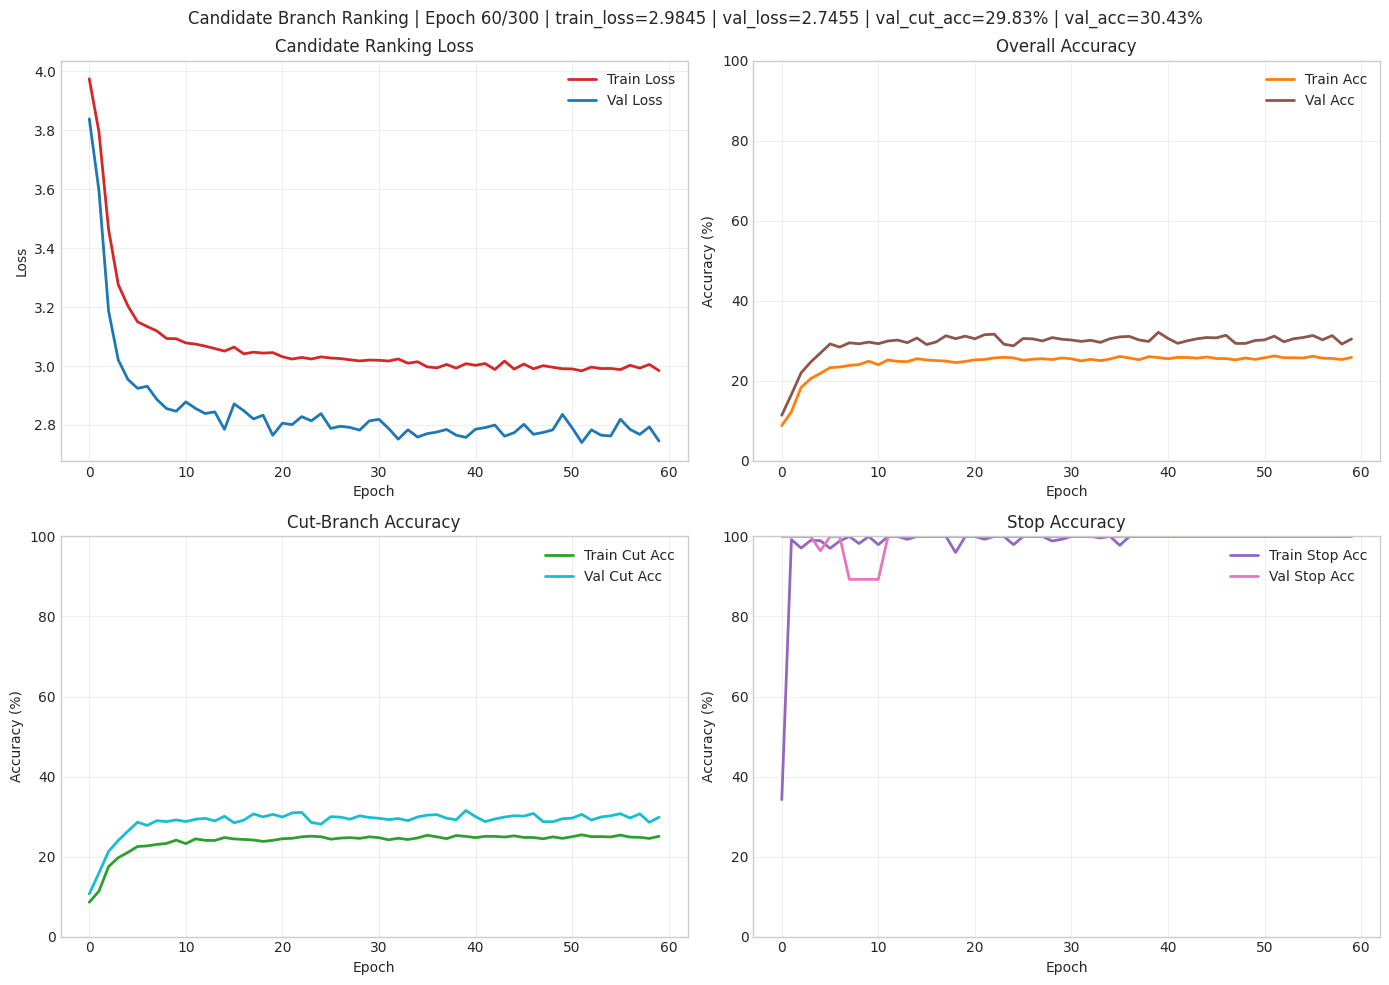

[Rank] Epoch 060/300 | train_loss=2.9845 | val_loss=2.7455 | train_acc=25.82% | val_acc=30.43% | train_cut_acc=25.07% | val_cut_acc=29.83% | train_stop_acc=100.00% | val_stop_acc=100.00% | best_epoch=40 | no_improve=20
[Rank] Early stopping triggered: validation cut accuracy has not improved for 20 epochs.

Candidate branch ranking baseline ready. If this still fails to generalize, the next step should be a skeleton GNN or explicit branch graph model.


In [23]:
# Alternative baseline: candidate branch ranking instead of global action-ID classification.
# 中文说明：上一版失败的核心原因，很可能不是“正则不够”，而是动作被建模成了跨树不共享语义的全局 branch_id 分类。
# 这一版改成：在每个时刻只对“当前树里真实存在的候选枝条”打分，并额外加入一个 STOP 选项。

from pathlib import Path
import json
import pickle
import re
from typing import Any, Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from IPython.display import clear_output
from torch.utils.data import DataLoader, Dataset, Subset

# =========================
# 1) Candidate ranking 配置
# =========================
RANK_DATA_ROOT = Path("./data/trajectories")
RANK_CHECKPOINT_DIR = Path("./checkpoints")
RANK_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RANK_EXPERT_ONLY = True
RANK_TREE_LEVEL_SPLIT = True
RANK_VAL_RATIO = 0.15
RANK_SPLIT_SEED = 42

RANK_MAX_CANDIDATES = 64
RANK_FEATURE_DIM = 15
RANK_BATCH_SIZE = 128
RANK_NUM_EPOCHS = 300
RANK_LR = 1e-3
RANK_WEIGHT_DECAY = 1e-4
RANK_HIDDEN_DIM = 128
RANK_DROPOUT = 0.20
RANK_FEATURE_NOISE_STD = 0.01
RANK_PLOT_EVERY = 5
RANK_EARLY_STOPPING_PATIENCE = 20
RANK_MIN_EPOCHS_BEFORE_STOP = 20
RANK_STOP_SAMPLE_WEIGHT = 1.25
RANK_STOP_ACTION = -1

rank_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Candidate ranking device:", rank_device)

# =========================
# 2) 工具函数
# =========================
def rank_load_serialized_trajectory(file_path: Path) -> Dict[str, Any]:
    suffix = file_path.suffix.lower()
    if suffix == ".npz":
        with np.load(file_path, allow_pickle=True) as data:
            return {k: data[k] for k in data.files}
    if suffix == ".pt":
        return torch.load(file_path, map_location="cpu")
    if suffix in {".pkl", ".pickle"}:
        with open(file_path, "rb") as f:
            return pickle.load(f)
    if suffix == ".json":
        with open(file_path, "r", encoding="utf-8") as f:
            return json.load(f)
    raise ValueError(f"Unsupported trajectory file type: {file_path}")


def rank_as_numpy_list(x: Any) -> List[np.ndarray]:
    if x is None:
        return []
    if isinstance(x, list):
        return [np.asarray(item) for item in x]
    if isinstance(x, tuple):
        return [np.asarray(item) for item in x]
    if isinstance(x, np.ndarray):
        if x.dtype == object:
            return [np.asarray(item) for item in x.tolist()]
        if x.ndim == 3:
            return [np.asarray(x[i]) for i in range(x.shape[0])]
        return [np.asarray(x)]
    if torch.is_tensor(x):
        x = x.detach().cpu().numpy()
        if x.ndim == 3:
            return [np.asarray(x[i]) for i in range(x.shape[0])]
        return [np.asarray(x)]
    return [np.asarray(x)]


def rank_find_trajectory_files(root: Path) -> List[Path]:
    if not root.exists():
        raise FileNotFoundError(f"数据目录不存在: {root}")
    files = [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in {".npz", ".pt", ".pkl", ".pickle", ".json"}
        and any(key in p.name.lower() for key in ("trajectory", "episode", "traj"))
    ]
    return sorted(files)


def rank_extract_tree_key(file_path: Path) -> str:
    match = re.search(r"(Lemon\d+_\d+)", file_path.stem)
    return match.group(1) if match else file_path.stem


def rank_infer_root_branch_id(skeleton_step: np.ndarray) -> Optional[int]:
    if skeleton_step.size == 0:
        return None
    parent_idx = np.round(skeleton_step[:, 4]).astype(int)
    branch_ids = np.round(skeleton_step[:, 5]).astype(int)
    root_mask = parent_idx <= 0
    if root_mask.any():
        vals, counts = np.unique(branch_ids[root_mask], return_counts=True)
        return int(vals[np.argmax(counts)])
    valid_branch_ids = [int(b) for b in np.unique(branch_ids) if int(b) >= 0]
    if not valid_branch_ids:
        return None
    return int(min(valid_branch_ids, key=lambda b: float(skeleton_step[branch_ids == b, 2].mean())))


def rank_build_candidate_tensor(
    point_cloud: np.ndarray,
    skeleton_step: np.ndarray,
    action_raw: int,
    rtg_value: float,
    timestep: int,
    max_candidates: int = RANK_MAX_CANDIDATES,
) -> Tuple[np.ndarray, np.ndarray, int, bool]:
    pc = np.asarray(point_cloud, dtype=np.float32).reshape(-1, 3)
    sk = np.asarray(skeleton_step, dtype=np.float32).reshape(-1, 6)

    finite_mask = np.isfinite(sk).all(axis=1)
    sk = sk[finite_mask]

    features = np.zeros((max_candidates + 1, RANK_FEATURE_DIM), dtype=np.float32)
    candidate_mask = np.zeros((max_candidates + 1,), dtype=np.bool_)
    stop_label = max_candidates

    if sk.size == 0:
        features[stop_label] = np.array([
            1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
            0.0, np.clip(float(timestep) / 30.0, 0.0, 1.0), np.tanh(float(rtg_value) / 3.0), 0.0,
        ], dtype=np.float32)
        candidate_mask[stop_label] = True
        return features, candidate_mask, stop_label, True

    branch_ids = np.round(sk[:, 5]).astype(int)
    root_branch = rank_infer_root_branch_id(sk)

    raw_candidates = [int(b) for b in np.unique(branch_ids) if int(b) >= 0 and int(b) != root_branch]
    if int(action_raw) != RANK_STOP_ACTION and int(action_raw) not in raw_candidates:
        raw_candidates.append(int(action_raw))

    all_xyz = sk[:, :3]
    if pc.size:
        all_xyz = np.concatenate([pc[:, :3], all_xyz], axis=0)

    bbox_min = all_xyz.min(axis=0)
    bbox_max = all_xyz.max(axis=0)
    bbox_span = np.maximum(bbox_max - bbox_min, 1e-6)
    xy_scale = float(np.linalg.norm(bbox_span[:2]) + 1e-6)
    z_scale = float(bbox_span[2] + 1e-6)
    global_scale = float(np.linalg.norm(bbox_span) + 1e-6)

    if root_branch is not None and np.any(branch_ids == root_branch):
        base = sk[branch_ids == root_branch, :3].mean(axis=0)
    else:
        base = sk[np.argmin(sk[:, 2]), :3]

    candidate_rows: List[Tuple[int, np.ndarray, float]] = []
    n_candidates_norm = np.clip(float(len(raw_candidates)) / float(max_candidates), 0.0, 1.0)
    timestep_norm = np.clip(float(timestep) / 30.0, 0.0, 1.0)
    rtg_norm = float(np.tanh(float(rtg_value) / 3.0))

    for branch_id in raw_candidates:
        branch_mask = branch_ids == int(branch_id)
        pts = sk[branch_mask, :3]
        radii = np.abs(sk[branch_mask, 3]) if branch_mask.any() else np.zeros((1,), dtype=np.float32)
        if pts.size == 0:
            continue

        centroid = pts.mean(axis=0)
        rel = centroid - base
        radial = float(np.linalg.norm(rel[:2]))
        vec_norm = float(np.linalg.norm(rel) + 1e-6)
        angle_deg = float(np.degrees(np.arccos(np.clip(rel[2] / vec_norm, -1.0, 1.0))))
        length = float(np.linalg.norm(pts.max(axis=0) - pts.min(axis=0)))
        inward_penalty = 1.0 - np.clip(radial / xy_scale, 0.0, 1.0)
        vertical_penalty = float(np.clip((35.0 - angle_deg) / 35.0, 0.0, 1.0))
        length_norm = float(np.clip(length / global_scale, 0.0, 2.0))
        heuristic_badness = 0.45 * inward_penalty + 0.35 * vertical_penalty + 0.20 * min(length_norm, 1.0)

        feat = np.array([
            0.0,
            radial / xy_scale,
            angle_deg / 180.0,
            length / global_scale,
            (centroid[2] - base[2]) / z_scale,
            (pts[:, 2].max() - base[2]) / z_scale,
            (pts[:, 2].min() - base[2]) / z_scale,
            float(radii.mean()) / global_scale,
            min(float(len(pts)) / 20.0, 2.0),
            (centroid[0] - base[0]) / xy_scale,
            (centroid[1] - base[1]) / xy_scale,
            n_candidates_norm,
            timestep_norm,
            rtg_norm,
            heuristic_badness,
        ], dtype=np.float32)
        candidate_rows.append((int(branch_id), feat, float(heuristic_badness)))

    candidate_rows.sort(key=lambda x: x[2], reverse=True)
    selected = candidate_rows[:max_candidates]

    if int(action_raw) != RANK_STOP_ACTION and all(bid != int(action_raw) for bid, _, _ in selected):
        target_row = next((row for row in candidate_rows if row[0] == int(action_raw)), None)
        if target_row is not None:
            if len(selected) < max_candidates:
                selected.append(target_row)
            elif selected:
                selected[-1] = target_row
            else:
                selected = [target_row]

    selected_ids = []
    for idx, (branch_id, feat, _) in enumerate(selected):
        features[idx] = feat
        candidate_mask[idx] = True
        selected_ids.append(int(branch_id))

    stop_feature = np.array([
        1.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        n_candidates_norm,
        timestep_norm,
        rtg_norm,
        0.0,
    ], dtype=np.float32)
    features[stop_label] = stop_feature
    candidate_mask[stop_label] = True

    if int(action_raw) == RANK_STOP_ACTION:
        label = stop_label
        is_stop = True
    else:
        if int(action_raw) not in selected_ids:
            label = stop_label
        else:
            label = selected_ids.index(int(action_raw))
        is_stop = False

    return features, candidate_mask, int(label), bool(is_stop)


# =========================
# 3) 数据集定义
# =========================
class BranchRankingDataset(Dataset):
    def __init__(self, data_root: Path, expert_only: bool = True) -> None:
        self.data_root = Path(data_root)
        self.expert_only = bool(expert_only)
        self.trajectory_files = rank_find_trajectory_files(self.data_root)
        if self.expert_only:
            self.trajectory_files = [p for p in self.trajectory_files if p.name.startswith("expert_traj_")]
        if not self.trajectory_files:
            raise FileNotFoundError(f"在 {self.data_root} 下未找到可用 expert 轨迹文件。")

        self.traj_cache: Dict[str, Dict[str, Any]] = {}
        self.samples: List[Tuple[Path, int]] = []
        self.sample_tree_keys: List[str] = []

        for file_path in self.trajectory_files:
            traj = rank_load_serialized_trajectory(file_path)
            self.traj_cache[str(file_path)] = traj

            point_clouds = rank_as_numpy_list(traj.get("point_clouds"))
            skeletons = rank_as_numpy_list(traj.get("skeletons"))
            actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
            rewards = np.asarray(traj.get("rewards", []), dtype=np.float32).reshape(-1)
            returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
            timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)

            seq_len = min(
                len(point_clouds),
                len(skeletons),
                len(actions),
                len(rewards),
                len(returns_to_go),
                len(timesteps),
            )
            if seq_len == 0:
                continue

            tree_key = rank_extract_tree_key(file_path)
            for t in range(seq_len):
                self.samples.append((file_path, int(t)))
                self.sample_tree_keys.append(tree_key)

        if not self.samples:
            raise ValueError("未构建出任何 step-level ranking 样本。")

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        file_path, step_idx = self.samples[index]
        traj = self.traj_cache[str(file_path)]

        point_clouds = rank_as_numpy_list(traj.get("point_clouds"))
        skeletons = rank_as_numpy_list(traj.get("skeletons"))
        actions = np.asarray(traj.get("actions", []), dtype=np.int64).reshape(-1)
        returns_to_go = np.asarray(traj.get("returns_to_go", []), dtype=np.float32).reshape(-1)
        timesteps = np.asarray(traj.get("timesteps", []), dtype=np.int64).reshape(-1)

        candidate_features, candidate_mask, label, is_stop = rank_build_candidate_tensor(
            point_cloud=point_clouds[step_idx],
            skeleton_step=skeletons[step_idx],
            action_raw=int(actions[step_idx]),
            rtg_value=float(returns_to_go[step_idx]),
            timestep=int(timesteps[step_idx]),
            max_candidates=RANK_MAX_CANDIDATES,
        )

        return {
            "candidate_features": torch.from_numpy(candidate_features),
            "candidate_mask": torch.from_numpy(candidate_mask.astype(np.bool_)),
            "label": torch.tensor(label, dtype=torch.long),
            "is_stop": torch.tensor(is_stop, dtype=torch.bool),
        }


# =========================
# 4) Tree-level split
# =========================
rank_full_dataset = BranchRankingDataset(RANK_DATA_ROOT, expert_only=RANK_EXPERT_ONLY)
rank_full_size = len(rank_full_dataset)
rank_tree_keys = list(rank_full_dataset.sample_tree_keys)
rank_unique_tree_keys = sorted(set(rank_tree_keys))

if RANK_TREE_LEVEL_SPLIT and len(rank_unique_tree_keys) >= 2:
    rng = np.random.default_rng(RANK_SPLIT_SEED)
    shuffled_tree_keys = rank_unique_tree_keys.copy()
    rng.shuffle(shuffled_tree_keys)

    rank_val_tree_count = max(1, int(round(len(shuffled_tree_keys) * RANK_VAL_RATIO)))
    rank_val_tree_count = min(rank_val_tree_count, len(shuffled_tree_keys) - 1)

    rank_val_tree_keys = set(shuffled_tree_keys[:rank_val_tree_count])
    rank_train_tree_keys = set(shuffled_tree_keys[rank_val_tree_count:])

    rank_train_indices = [i for i, key in enumerate(rank_tree_keys) if key in rank_train_tree_keys]
    rank_val_indices = [i for i, key in enumerate(rank_tree_keys) if key in rank_val_tree_keys]

    rank_train_dataset = Subset(rank_full_dataset, rank_train_indices)
    rank_val_dataset = Subset(rank_full_dataset, rank_val_indices)
else:
    rank_val_size = max(1, int(round(rank_full_size * RANK_VAL_RATIO))) if rank_full_size >= 2 else 0
    rank_val_size = min(rank_val_size, rank_full_size - 1) if rank_full_size >= 2 else 0
    rank_train_size = rank_full_size - rank_val_size
    split_generator = torch.Generator().manual_seed(RANK_SPLIT_SEED)
    rank_train_dataset, rank_val_dataset = random_split(
        rank_full_dataset,
        [rank_train_size, rank_val_size],
        generator=split_generator,
    )
    rank_val_tree_count = 0

rank_train_loader = DataLoader(
    rank_train_dataset,
    batch_size=min(RANK_BATCH_SIZE, max(1, len(rank_train_dataset))),
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)
rank_val_loader = DataLoader(
    rank_val_dataset,
    batch_size=min(RANK_BATCH_SIZE, max(1, len(rank_val_dataset))),
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

print("\n===== Candidate Ranking Dataset =====")
print("原始 expert 轨迹数:", len(rank_full_dataset.trajectory_files))
print("step-level 样本数:", rank_full_size)
print("训练样本数:", len(rank_train_dataset))
print("验证样本数:", len(rank_val_dataset))
print("唯一树数量:", len(rank_unique_tree_keys))
print("候选上限 + STOP:", RANK_MAX_CANDIDATES + 1)
print("特征维度:", RANK_FEATURE_DIM)


# =========================
# 5) 排序模型
# =========================
class CandidateBranchRanker(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int = 128, dropout: float = 0.2) -> None:
        super().__init__()
        self.scorer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, candidate_features: torch.Tensor, candidate_mask: torch.Tensor) -> torch.Tensor:
        scores = self.scorer(candidate_features).squeeze(-1)
        scores = scores.masked_fill(~candidate_mask, -1e4)
        return scores


rank_model = CandidateBranchRanker(
    input_dim=RANK_FEATURE_DIM,
    hidden_dim=RANK_HIDDEN_DIM,
    dropout=RANK_DROPOUT,
).to(rank_device)

rank_optimizer = torch.optim.AdamW(rank_model.parameters(), lr=RANK_LR, weight_decay=RANK_WEIGHT_DECAY)
rank_criterion = nn.CrossEntropyLoss(reduction="none")


def rank_compute_metrics(batch: Dict[str, torch.Tensor], is_training: bool = False) -> Dict[str, Any]:
    candidate_features = batch["candidate_features"].to(rank_device, non_blocking=True).float()
    candidate_mask = batch["candidate_mask"].to(rank_device, non_blocking=True).bool()
    labels = batch["label"].to(rank_device, non_blocking=True).long()
    is_stop = batch["is_stop"].to(rank_device, non_blocking=True).bool()

    if is_training and RANK_FEATURE_NOISE_STD > 0:
        candidate_features = candidate_features.clone()
        noise = torch.randn_like(candidate_features[..., 1:]) * RANK_FEATURE_NOISE_STD
        candidate_features[..., 1:] = candidate_features[..., 1:] + noise * candidate_mask.unsqueeze(-1).float()

    scores = rank_model(candidate_features, candidate_mask)
    per_sample_ce = rank_criterion(scores, labels)
    sample_weights = torch.where(
        is_stop,
        torch.full_like(per_sample_ce, RANK_STOP_SAMPLE_WEIGHT),
        torch.ones_like(per_sample_ce),
    )
    loss = (per_sample_ce * sample_weights).sum() / sample_weights.sum().clamp_min(1.0)

    with torch.no_grad():
        preds = scores.argmax(dim=-1)
        acc = (preds == labels).float().mean().item()

        stop_acc = (
            (preds[is_stop] == labels[is_stop]).float().mean().item()
            if is_stop.any() else float("nan")
        )
        cut_mask = ~is_stop
        cut_acc = (
            (preds[cut_mask] == labels[cut_mask]).float().mean().item()
            if cut_mask.any() else float("nan")
        )

    return {
        "loss": loss,
        "acc": acc,
        "stop_acc": stop_acc,
        "cut_acc": cut_acc,
    }


# =========================
# 6) 训练循环
# =========================
rank_best_score = float("inf")
rank_best_epoch = 0
rank_epochs_without_improve = 0

rank_train_loss_history: List[float] = []
rank_val_loss_history: List[float] = []
rank_train_acc_history: List[float] = []
rank_val_acc_history: List[float] = []
rank_train_stop_acc_history: List[float] = []
rank_val_stop_acc_history: List[float] = []
rank_train_cut_acc_history: List[float] = []
rank_val_cut_acc_history: List[float] = []

for epoch in range(1, RANK_NUM_EPOCHS + 1):
    rank_model.train()
    train_losses, train_accs, train_stop_accs, train_cut_accs = [], [], [], []

    for batch in rank_train_loader:
        rank_optimizer.zero_grad(set_to_none=True)
        metrics = rank_compute_metrics(batch, is_training=True)
        metrics["loss"].backward()
        torch.nn.utils.clip_grad_norm_(rank_model.parameters(), max_norm=1.0)
        rank_optimizer.step()

        train_losses.append(float(metrics["loss"].item()))
        train_accs.append(float(metrics["acc"]))
        train_stop_accs.append(float(metrics["stop_acc"]))
        train_cut_accs.append(float(metrics["cut_acc"]))

    rank_model.eval()
    val_losses, val_accs, val_stop_accs, val_cut_accs = [], [], [], []
    with torch.no_grad():
        for batch in rank_val_loader:
            metrics = rank_compute_metrics(batch, is_training=False)
            val_losses.append(float(metrics["loss"].item()))
            val_accs.append(float(metrics["acc"]))
            val_stop_accs.append(float(metrics["stop_acc"]))
            val_cut_accs.append(float(metrics["cut_acc"]))

    def _safe_nanmean(values: List[float]) -> float:
        valid = [float(v) for v in values if np.isfinite(v)]
        return float(np.mean(valid)) if valid else float("nan")

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    train_acc = _safe_nanmean(train_accs)
    val_acc = _safe_nanmean(val_accs)
    train_stop_acc = _safe_nanmean(train_stop_accs)
    val_stop_acc = _safe_nanmean(val_stop_accs)
    train_cut_acc = _safe_nanmean(train_cut_accs)
    val_cut_acc = _safe_nanmean(val_cut_accs)

    rank_train_loss_history.append(train_loss)
    rank_val_loss_history.append(val_loss)
    rank_train_acc_history.append(train_acc)
    rank_val_acc_history.append(val_acc)
    rank_train_stop_acc_history.append(train_stop_acc)
    rank_val_stop_acc_history.append(val_stop_acc)
    rank_train_cut_acc_history.append(train_cut_acc)
    rank_val_cut_acc_history.append(val_cut_acc)

    if np.isfinite(val_cut_acc):
        current_score = -val_cut_acc
    elif np.isfinite(val_acc):
        current_score = -val_acc
    else:
        current_score = val_loss

    if current_score < rank_best_score - 1e-6:
        rank_best_score = current_score
        rank_best_epoch = epoch
        rank_epochs_without_improve = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state": rank_model.state_dict(),
                "optimizer_state": rank_optimizer.state_dict(),
                "val_cut_acc": val_cut_acc,
                "val_acc": val_acc,
                "val_loss": val_loss,
                "config": {
                    "max_candidates": RANK_MAX_CANDIDATES,
                    "feature_dim": RANK_FEATURE_DIM,
                    "hidden_dim": RANK_HIDDEN_DIM,
                    "dropout": RANK_DROPOUT,
                },
            },
            RANK_CHECKPOINT_DIR / "candidate_ranker_best.pt",
        )
    else:
        rank_epochs_without_improve += 1

    if epoch % RANK_PLOT_EVERY == 0:
        clear_output(wait=True)
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        axes[0, 0].plot(rank_train_loss_history, label="Train Loss", color="tab:red", linewidth=2)
        axes[0, 0].plot(rank_val_loss_history, label="Val Loss", color="tab:blue", linewidth=2)
        axes[0, 0].set_title("Candidate Ranking Loss")
        axes[0, 0].set_xlabel("Epoch")
        axes[0, 0].set_ylabel("Loss")
        axes[0, 0].grid(True, alpha=0.3)
        axes[0, 0].legend()

        axes[0, 1].plot([x * 100 for x in rank_train_acc_history], label="Train Acc", color="tab:orange", linewidth=2)
        axes[0, 1].plot([x * 100 for x in rank_val_acc_history], label="Val Acc", color="tab:brown", linewidth=2)
        axes[0, 1].set_title("Overall Accuracy")
        axes[0, 1].set_xlabel("Epoch")
        axes[0, 1].set_ylabel("Accuracy (%)")
        axes[0, 1].set_ylim(0, 100)
        axes[0, 1].grid(True, alpha=0.3)
        axes[0, 1].legend()

        axes[1, 0].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_train_cut_acc_history], label="Train Cut Acc", color="tab:green", linewidth=2)
        axes[1, 0].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_val_cut_acc_history], label="Val Cut Acc", color="tab:cyan", linewidth=2)
        axes[1, 0].set_title("Cut-Branch Accuracy")
        axes[1, 0].set_xlabel("Epoch")
        axes[1, 0].set_ylabel("Accuracy (%)")
        axes[1, 0].set_ylim(0, 100)
        axes[1, 0].grid(True, alpha=0.3)
        axes[1, 0].legend()

        axes[1, 1].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_train_stop_acc_history], label="Train Stop Acc", color="tab:purple", linewidth=2)
        axes[1, 1].plot([x * 100 if np.isfinite(x) else np.nan for x in rank_val_stop_acc_history], label="Val Stop Acc", color="tab:pink", linewidth=2)
        axes[1, 1].set_title("Stop Accuracy")
        axes[1, 1].set_xlabel("Epoch")
        axes[1, 1].set_ylabel("Accuracy (%)")
        axes[1, 1].set_ylim(0, 100)
        axes[1, 1].grid(True, alpha=0.3)
        axes[1, 1].legend()

        fig.suptitle(
            f"Candidate Branch Ranking | Epoch {epoch}/{RANK_NUM_EPOCHS} | "
            f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
            f"val_cut_acc={val_cut_acc * 100:.2f}% | val_acc={val_acc * 100:.2f}%",
            fontsize=12,
        )
        plt.tight_layout()
        plt.show()
        plt.close(fig)

    print(
        f"[Rank] Epoch {epoch:03d}/{RANK_NUM_EPOCHS} | "
        f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
        f"train_acc={train_acc * 100:.2f}% | val_acc={val_acc * 100:.2f}% | "
        f"train_cut_acc={train_cut_acc * 100:.2f}% | val_cut_acc={val_cut_acc * 100:.2f}% | "
        f"train_stop_acc={train_stop_acc * 100:.2f}% | val_stop_acc={val_stop_acc * 100:.2f}% | "
        f"best_epoch={rank_best_epoch} | no_improve={rank_epochs_without_improve}"
    )

    if epoch >= RANK_MIN_EPOCHS_BEFORE_STOP and rank_epochs_without_improve >= RANK_EARLY_STOPPING_PATIENCE:
        print(
            f"[Rank] Early stopping triggered: validation cut accuracy has not improved for {rank_epochs_without_improve} epochs."
        )
        break

print("\nCandidate branch ranking baseline ready. If this still fails to generalize, the next step should be a skeleton GNN or explicit branch graph model.")